# 02 · Lọc và phân ngưỡng — TV3
So sánh 110 cấu hình trên cùng 671 ảnh validation. Lee trên PNG là phép thử công thức, không phải lọc sigma0 đã hiệu chuẩn.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sar_oil import core, reference
from sar_oil.data import records, read_pair, MANIFEST
from sar_oil.experiments import OUT
def table(rows, columns):
    def value(x): return (f'{x:.3e}' if 0<abs(x)<1e-4 else f'{x:.6f}') if isinstance(x,float) else str(x)
    display(HTML('<table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in rows)+'</table>'))
def load(name):
    p=OUT/name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Run python scripts/sos.py reproduce first.')
    return json.loads(p.read_text(encoding='utf-8'))


## Vì sao chọn Lee?
Chạy `python scripts/sos_experiments/explain_selection.py --workers 6` để tái tạo bằng chứng. So sánh dưới đây giữ Otsu, morphology none, min_area16 cố định, chỉ thay bộ lọc trên toàn bộ 671 ảnh validation. Đây là đánh giá tạo ứng viên, chưa chứng minh bộ lọc tối ưu cho mọi classifier. F1-band 0.005 là quy ước, không phải định lý.

filter,tp,fp,fn,precision,recall,f1,delta_f1,bootstrap_interval
{'name': 'none'},518,39283,2222,0.013015,0.189051,0.024353,0.061168,"[0.05337422008062099, 0.06933512735115559]"
"{'name': 'median', 'size': 3}",758,50479,1982,0.014794,0.276642,0.028086,0.057435,"[0.050752736117993635, 0.06452302604910992]"
"{'name': 'median', 'size': 5}",910,36046,1830,0.024624,0.332117,0.045848,0.039673,"[0.03459538704345683, 0.045092583745675714]"
"{'name': 'gaussian', 'sigma': 0.8}",794,47039,1946,0.016599,0.289781,0.031400,0.054121,"[0.047649065372225234, 0.060781657549273935]"
"{'name': 'gaussian', 'sigma': 1.2}",895,40877,1845,0.021426,0.326642,0.040214,0.045307,"[0.039777765550882124, 0.0513144853610523]"
"{'name': 'lee', 'size': 3, 'looks': 1}",821,46341,1919,0.017408,0.299635,0.032904,0.052616,"[0.04624415547429199, 0.059174402057554365]"
"{'name': 'lee', 'size': 3, 'looks': 4}",822,46897,1918,0.017226,0.300000,0.032581,0.052940,"[0.04658720713884638, 0.05948625849006982]"
"{'name': 'lee', 'size': 5, 'looks': 1}",961,32247,1779,0.028939,0.350730,0.053466,0.032055,"[0.02776513790416906, 0.03670924325688198]"
"{'name': 'lee', 'size': 5, 'looks': 4}",967,32486,1773,0.028906,0.352920,0.053436,0.032085,"[0.02810725431118844, 0.036616047170707176]"
"{'name': 'lee', 'size': 7, 'looks': 1}",1034,20770,1706,0.047422,0.377372,0.084257,0.001264,"[-0.0004391554527122182, 0.003128761679309646]"


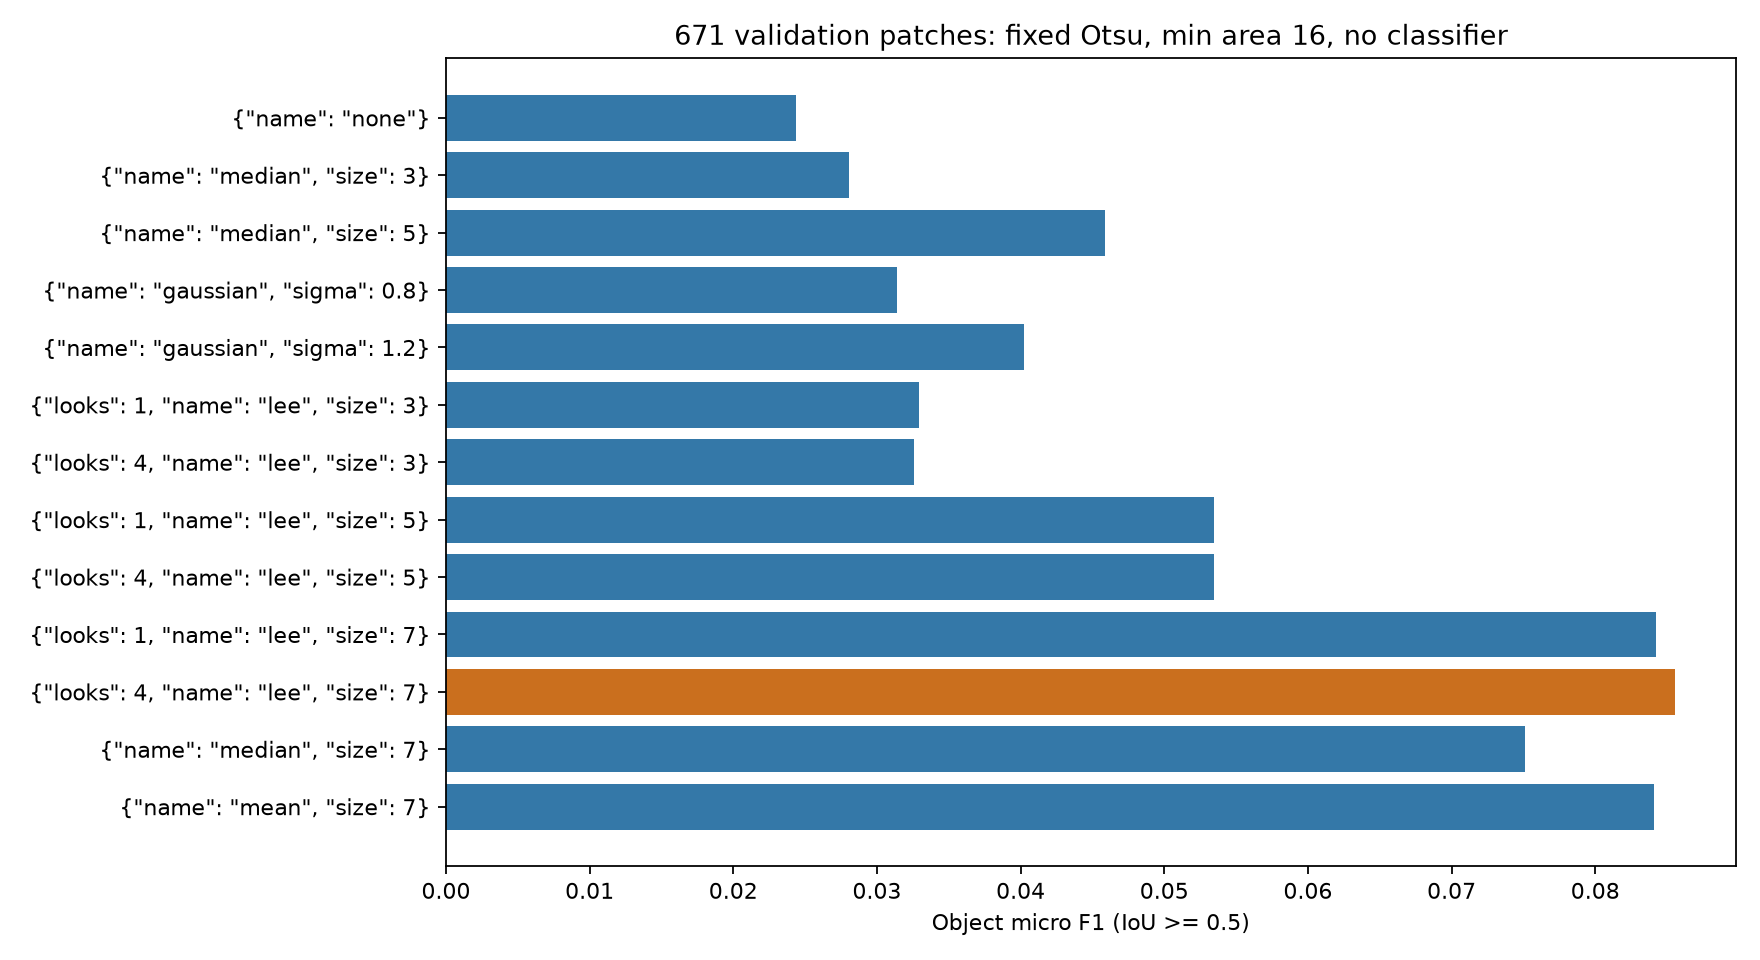

Lấy mẫu lại theo patch, sau lựa chọn; chưa bảo đảm độc lập cảnh hoặc hiệu chỉnh nhiều so sánh.
Lee7,L4 so với {'name': 'lee', 'size': 7, 'looks': 1} : ΔF1=0.001264, interval=[-0.000439, 0.003129]
Chưa có bằng chứng rõ ràng Lee7,L4 vượt phương án này trong phân tích hiện tại.
Lee7,L4 so với {'name': 'mean', 'size': 7} : ΔF1=0.001400, interval=[-0.000307, 0.003267]
Chưa có bằng chứng rõ ràng Lee7,L4 vượt phương án này trong phân tích hiện tại.
Mean7 và median7 là đối chứng bổ sung sau lựa chọn; không đổi mô hình đã khóa.
Đối chiếu NumPy cho đối chứng bổ sung: [{'filter': {'name': 'median', 'size': 7}, 'images': 671, 'max_abs_error': 0.0, 'passed': True}, {'filter': {'name': 'mean', 'size': 7}, 'images': 671, 'max_abs_error': 7.298606163885779e-13, 'passed': True}]
Bằng chứng và số đếm từng ảnh: D:\Codin\utc-code\HK4_1\XLA\BTL\results\sos\selection_evidence\per_image.json


In [2]:
evidence=load('selection_evidence/evidence.json')
table([dict(filter=str(r['filter']),**r['metrics'],delta_f1=r['lee_minus_filter_f1'],bootstrap_interval=r['paired_patch_bootstrap_95_interval']) for r in evidence['controlled_filters']],['filter','tp','fp','fn','precision','recall','f1','delta_f1','bootstrap_interval'])
from IPython.display import Image as NotebookImage
display(NotebookImage(filename=str(OUT/'selection_evidence/filters_fixed_otsu.png')))
print('Lấy mẫu lại theo patch, sau lựa chọn; chưa bảo đảm độc lập cảnh hoặc hiệu chỉnh nhiều so sánh.')
for row in evidence['controlled_filters']:
    if row['filter'] in ({'name':'mean','size':7},{'name':'lee','size':7,'looks':1}):
        low,high=row['paired_patch_bootstrap_95_interval']
        print('Lee7,L4 so với',row['filter'],':',f'ΔF1={row["lee_minus_filter_f1"]:.6f}, interval=[{low:.6f}, {high:.6f}]')
        if low<=0<=high: print('Chưa có bằng chứng rõ ràng Lee7,L4 vượt phương án này trong phân tích hiện tại.')
print('Mean7 và median7 là đối chứng bổ sung sau lựa chọn; không đổi mô hình đã khóa.')
print('Đối chiếu NumPy cho đối chứng bổ sung:',evidence['supplementary_numpy_checks'])
print('Bằng chứng và số đếm từng ảnh:',OUT/'selection_evidence/per_image.json')

Lee đang cài: noise=m²/L; w=max(v−noise,0)/max(v,1e−12); output=m+w·(input−m). Ở vùng phương sai nhỏ, đầu ra gần trung bình cục bộ; ở vùng phương sai lớn, giữ một phần chênh lệch. Đây là lý do khảo sát, không phải bảo đảm tăng F1. L trên PNG là tham số thực nghiệm, chưa phải số looks vật lý đã xác minh.

In [3]:
import inspect
print(inspect.getsource(core.filter_image))
strict=evidence['strict_f1_winner']; selected=load('selected.json')
table([dict(choice='Tối đa F1',filter=str(strict['config']['filter']),model=str(strict['params']),**strict['metrics']),dict(choice='Quy tắc đã dùng',filter=str(selected['config']['filter']),model=str(selected['params']),**selected['metrics'])],['choice','filter','model','recall','f1'])
print('Quy tắc:',evidence['selection_rule'])
print('C=10 và C=1 có cùng F1/Recall tại cấu hình đã chọn; tie-break thời gian một lần chưa chứng minh C=10 tốt hơn.')

def filter_image(a, name="none", size=3, sigma=0.8, looks=1):
    a = np.asarray(a, dtype=float)
    if name == "none":
        return a.copy()
    if name == "median":
        return np.median(
            sliding_window_view(np.pad(a, size // 2, mode="reflect"), (size, size)), axis=(-2, -1)
        )
    if name == "gaussian":
        x = np.arange(-2, 3)
        g = np.exp(-x * x / (2 * sigma * sigma))
        g /= g.sum()
        return correlate(correlate(a, g[None, :]), g[:, None])
    if name == "lee":
        m = mean_filter(a, size)
        v = np.maximum(mean_filter(a * a, size) - m * m, 0)
        noise = m * m / looks
        weight = np.maximum(v - noise, 0) / np.maximum(v, 1e-12)
        return m + weight * (a - m)
    raise ValueError(name)



choice,filter,model,recall,f1
Tối đa F1,"{'name': 'lee', 'size': 7, 'looks': 1}",{'C': 10},0.367518,0.343452
Quy tắc đã dùng,"{'name': 'lee', 'size': 7, 'looks': 4}",{'C': 10},0.370803,0.340312


Quy tắc: {'f1_band': 0.005, 'priority': ['recall descending', 'recorded seconds ascending', 'id ascending']}
C=10 và C=1 có cùng F1/Recall tại cấu hình đã chọn; tie-break thời gian một lần chưa chứng minh C=10 tốt hơn.


filter,threshold,precision,recall,f1,pixel_iou,seconds
"{'name': 'lee', 'size': 7, 'looks': 4}",{'name': 'otsu'},0.048137,0.382847,0.085521,0.562927,4.874386
"{'name': 'lee', 'size': 7, 'looks': 1}",{'name': 'otsu'},0.047422,0.377372,0.084257,0.564549,4.918661
"{'name': 'lee', 'size': 5, 'looks': 4}",{'name': 'otsu'},0.028906,0.352920,0.053436,0.535529,4.952544
"{'name': 'lee', 'size': 5, 'looks': 1}",{'name': 'otsu'},0.028939,0.350730,0.053466,0.536463,4.813729
"{'name': 'median', 'size': 5}",{'name': 'otsu'},0.024624,0.332117,0.045848,0.524057,28.364689
"{'name': 'gaussian', 'sigma': 1.2}",{'name': 'otsu'},0.021426,0.326642,0.040214,0.511780,3.318479
"{'name': 'lee', 'size': 3, 'looks': 4}",{'name': 'otsu'},0.017226,0.300000,0.032581,0.490691,4.848833
"{'name': 'lee', 'size': 3, 'looks': 1}",{'name': 'otsu'},0.017408,0.299635,0.032904,0.490930,4.783311
"{'name': 'gaussian', 'sigma': 0.8}",{'name': 'otsu'},0.016599,0.289781,0.031400,0.484870,3.425894
"{'name': 'median', 'size': 3}",{'name': 'otsu'},0.014794,0.276642,0.028086,0.478045,11.614368


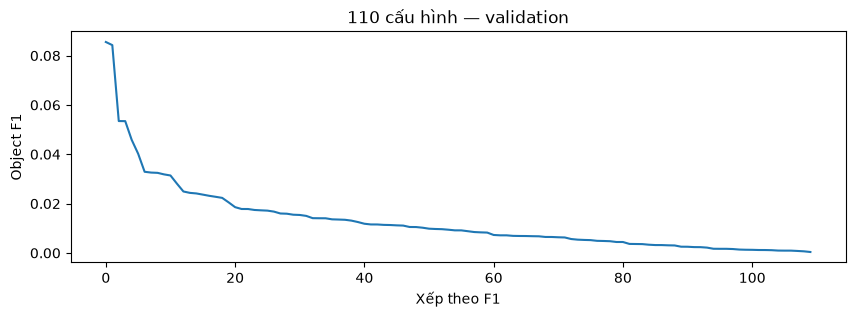

In [4]:
rows=load('screen.json')
table([dict(filter=str(r['config']['filter']),threshold=str(r['config']['threshold']),**r['metrics'],seconds=r['seconds']) for r in rows[:15]],['filter','threshold','precision','recall','f1','pixel_iou','seconds'])
fig,ax=plt.subplots(figsize=(10,3)); ax.plot(sorted([r['metrics']['f1'] or 0 for r in rows],reverse=True)); ax.set(xlabel='Xếp theo F1',ylabel='Object F1',title='110 cấu hình — validation'); plt.show()

Mean cục bộ dùng summed-area table. Niblack: I < mean − k·std. Otsu dùng 256 bin cố định [0,1]. Đệm reflect không lặp pixel mép. Lee reference ghép công thức bằng SciPy, không phải API Lee độc lập.

Sai số lọc lớn nhất:

 1.3592182934729635e-12


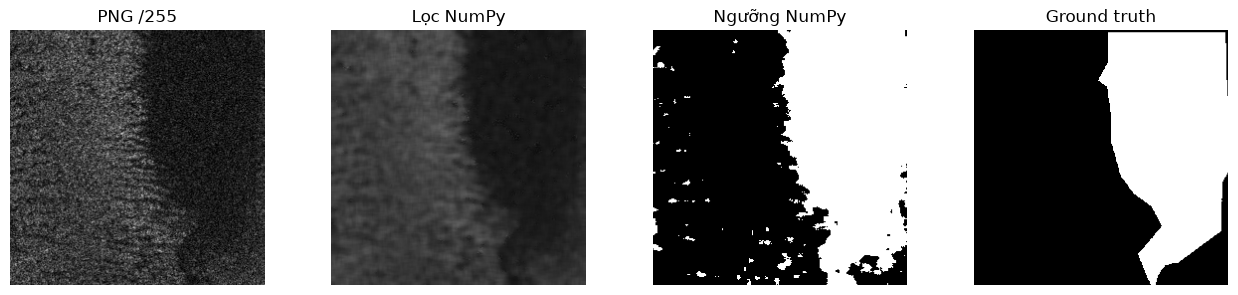

config,max_abs_error,numpy_seconds,reference_seconds,passed
"{""looks"": 1, ""name"": ""lee"", ""size"": 3}",1.006e-11,0.004288,0.002933,True
"{""looks"": 1, ""name"": ""lee"", ""size"": 5}",2.573e-12,0.003805,0.002712,True
"{""looks"": 1, ""name"": ""lee"", ""size"": 7}",6.274e-13,0.004152,0.002720,True
"{""looks"": 4, ""name"": ""lee"", ""size"": 3}",1.382e-11,0.003858,0.002587,True
"{""looks"": 4, ""name"": ""lee"", ""size"": 5}",4.338e-12,0.003894,0.002761,True
"{""looks"": 4, ""name"": ""lee"", ""size"": 7}",2.737e-12,0.004340,0.002708,True
"{""name"": ""gaussian"", ""sigma"": 0.8}",3.331e-16,0.001426,0.001282,True
"{""name"": ""gaussian"", ""sigma"": 1.2}",3.331e-16,0.001295,0.001188,True
"{""name"": ""median"", ""size"": 3}",0.000000,0.016310,0.011312,True
"{""name"": ""median"", ""size"": 5}",0.000000,0.047031,0.037412,True


Đối chiếu trên 8 ảnh SOS validation thật; thời gian trung bình/ảnh.


In [5]:
a,g=read_pair(next(r for r in records('validation') if not r['empty']))
best=rows[0]['config']; n=core.filter_image(a,**best['filter']); r=reference.filter_image(a,**best['filter'])
print('Sai số lọc lớn nhất:',np.max(np.abs(n-r)))
fig,axes=plt.subplots(1,4,figsize=(13,3))
for ax,img,title in zip(axes,[a,n,core.threshold(n,**best['threshold']),g],['PNG /255','Lọc NumPy','Ngưỡng NumPy','Ground truth']): ax.imshow(img,cmap='gray',vmin=0,vmax=1); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
checks=load('verification_real.json')['checks']
aggregated=[]
for config in {json.dumps(c['config'],sort_keys=True) for c in checks if c['operation']=='filter'}:
    same=[c for c in checks if c['operation']=='filter' and json.dumps(c['config'],sort_keys=True)==config]
    aggregated.append(dict(config=config,max_abs_error=max(c['max_abs_error'] for c in same),numpy_seconds=np.mean([c['numpy_seconds'] for c in same]),reference_seconds=np.mean([c['reference_seconds'] for c in same]),passed=all(c['passed'] for c in same)))
table(sorted(aggregated,key=lambda c:c['config']),['config','max_abs_error','numpy_seconds','reference_seconds','passed'])
print('Đối chiếu trên 8 ảnh SOS validation thật; thời gian trung bình/ảnh.')